# 07 · 三维 FNO：立方体中的椭圆 PDE

**前置：** 05 二维 FNO。**目标：** 实现真正的三个空间维度 $(x,y,z)$ 的 Fourier 神经算子，理解 3D rFFT 的四个频率角块，并评估更密网格。

在周期单位立方体 $[0,1)^3$ 上解 $-\Delta u+u=f$，其中 $\Delta=\partial_{xx}+\partial_{yy}+\partial_{zz}$。这里三轴都是空间，不是把二维空间加时间叫“三维”。反应项 $+u$ 保证零频率可逆。

训练 $v=Su$，$S=1+4\pi^2$。频谱参考解为 $\widehat u(\boldsymbol k)=\widehat f(\boldsymbol k)/(1+4\pi^2|\boldsymbol k|^2)$。所有边界均为周期；这不是带物体壁面的流动案例。

参考：[FNO 原论文](https://arxiv.org/abs/2010.08895)、[rfftn 接口](https://docs.pytorch.org/docs/stable/generated/torch.fft.rfftn.html)。

## 原理详解 A：从二维提升到真正三维空间

三维 Laplace 是三条空间轴的二阶导数之和：
$$
\Delta u=u_{xx}+u_{yy}+u_{zz}.
$$
对波矢 $\boldsymbol k=(k_x,k_y,k_z)$，基函数 $e^{i2\pi\boldsymbol k\cdot\boldsymbol x}$ 满足
$$
-\Delta e^{i2\pi\boldsymbol k\cdot\boldsymbol x}
=4\pi^2|\boldsymbol k|^2e^{i2\pi\boldsymbol k\cdot\boldsymbol x}.
$$
所以三维解公式只是把二维的 $k^2+l^2$ 换成三维平方和。真正增加的难度在于体积存储、更多频率组合和网络运算，而不是解析分母本身。

例如 $u_*=\sin[2\pi(x+y+z)]$ 的波矢为 $(1,1,1)$，平方模长为 3，forcing 是 $(1+12\pi^2)u_*$。制造解检查必须包含三个方向的导数，不能只拿 $u(x)$ 来证明代码正确处理了 y 和 z。

如果区域长宽高分别为 $L_x,L_y,L_z$，则谱符号改为
$$
1+4\pi^2\left(\frac{k_x^2}{L_x^2}
+\frac{k_y^2}{L_y^2}+\frac{k_z^2}{L_z^2}\right).
$$
空间各向异性既可以来自域长度，也可以来自不同方向的扩散系数，需要在物理模型中明确。

## 原理详解 B：三维频谱四角块与 einsum

rFFTN 只压缩最后一个参与变换的维度：
$$
[B,C,N_x,N_y,N_z]\to
[B,C,N_x,N_y,\lfloor N_z/2\rfloor+1].
$$
前两轴各有正、负频率，保留区域因此分成四个角块。最后一轴不储存负频率，是利用整组波矢的实信号共轭对称，不是忽略 z 方向的一半信息。

代码对每块做
$$
\widehat w_o(k_x,k_y,k_z)=
\sum_iR_{i,o,k_x,k_y,k_z}\widehat v_i(k_x,k_y,k_z).
$$
频率位置固定时只求输入通道 i 的和，不能在 k、l、m 三个频率轴上也求和，否则会破坏逐模式乘子含义。

| 阶段 | 形状或含义 |
|---|---|
| 物理标量输入 | $[B,1,N_x,N_y,N_z]$ |
| 六个位置通道 | 三轴 sin 与 cos |
| lifting | 通道 $7\to C$ |
| 频谱层 | 四块各有 $C\times C\times m^3$ 复数权重 |
| 1×1×1 卷积 | 每个体素上的通道线性变换 |
| projection | $C\to16\to1$ |
| 返回标量体积 | $[B,N_x,N_y,N_z]$ |

一层频谱参数包含约 $4C^2m^3$ 个复数元素，每个复数元素包含两个实数分量。代码用 numel 统计元素数量，复数元素不会自动算成两个，所以该打印值不等同于全部实自由度数量。

模式数量增加会按立方增长频谱参数；网格增加主要影响激活与 FFT，而不是这套固定模式参数。

## 原理详解 C：三维计算成本与残差解释

记 $M=N_xN_yN_z$。FFT 约为 $O(CM\log M)$，频率通道混合约为 $O(4C^2m^3)$，点态通道混合约为 $O(C^2M)$，还需乘 batch 与层数。每轴分辨率翻倍，M 变成八倍；反向传播还要保留中间激活，因此内存增长不能只看输入文件大小。

切片是在体积中取二维截面，不能识别所有三维区域的误差。测试相对范数先 flatten 整个体积，使用的是所有体素，再单独绘制两个方向的中心切片。

设预测误差为 e，物理残差的模式是
$$
\widehat r_{\boldsymbol k}
=(1+4\pi^2|\boldsymbol k|^2)\widehat e_{\boldsymbol k}.
$$
因此较小的体积误差不保证同样小的残差，特别是网络在高频产生小噪声时。本章诊断使用双精度，减少 FFT 导数的舍入误差；它不能消除模型已经产生的高频误差。

跨分辨率实验是在同一单位立方体、同一测试系数下复用模型。换成复杂物体几何、壁面边界或不同域尺度，属于新的问题定义，需要额外几何输入、边界处理或重新训练。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic("matplotlib", "inline")
from tutorial_utils import *
from tutorial_3d_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 三维函数族与可靠参考解

公共数据函数使用三维波矢，含沿单轴、混合三轴和负分量的 sin/cos 模式。系数除以 $|\boldsymbol k|^2$，产生光滑初值；这是一类受控函数族，不能据此声称能处理任意高频 forcing。

默认 64 条训练函数、16 条验证函数、16 条测试函数，网格 $12^3$。快速模式使用更少样本与 $8^3$ 网格。先用单个三维制造解验证求解器。

input scalar volumes: torch.Size([64, 12, 12, 12]) training output: torch.Size([64, 12, 12, 12])


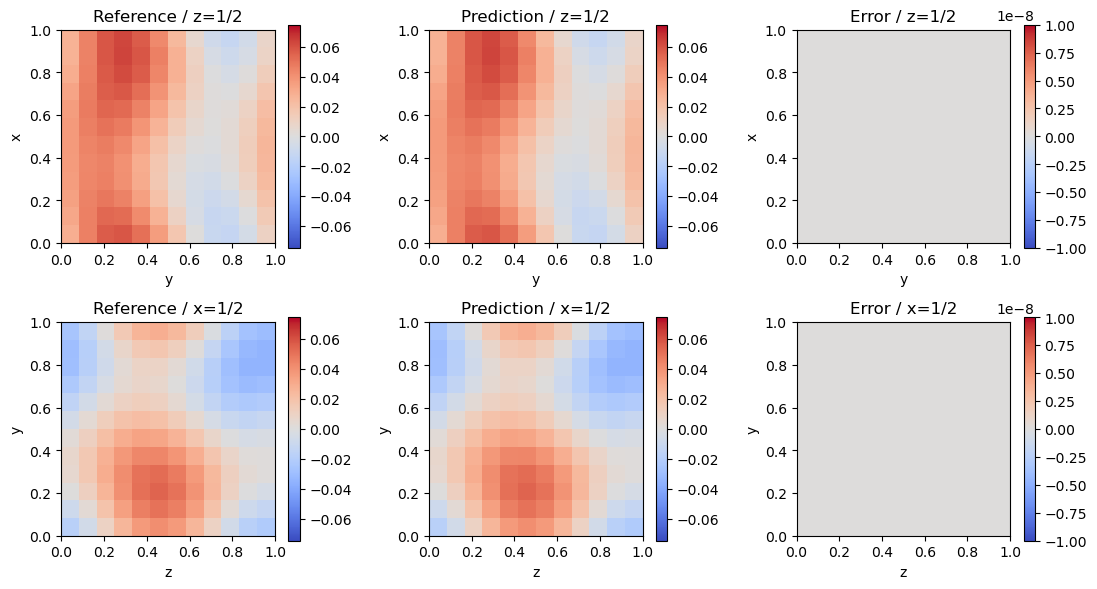

In [2]:
N = 8 if SMOKE else 12
ntrain,ntest = (16,4) if SMOKE else (64,16)
SCALE = 1+4*torch.pi**2
atrain = torch.randn(ntrain,NCOEFF)
aval,atest = torch.randn(ntest,NCOEFF),torch.randn(ntest,NCOEFF)
ftrain,fval,ftest = [field3d(a,N) for a in [atrain,aval,atest]]
vtrain,vval,vtest = [SCALE*screened_poisson3d(f) for f in [ftrain,fval,ftest]]
grid = periodic_grid3d(N,dtype=torch.float64)
single = torch.sin(2*torch.pi*(grid[0]+grid[1]+grid[2]))[None]
single_f = (1+12*torch.pi**2)*single
assert (screened_poisson3d(single_f)-single).abs().max()<1e-10
print("input scalar volumes:",ftrain.shape,"training output:",vtrain.shape)
show_volume_slices(vtest/SCALE,vtest/SCALE)

## 2. 为什么需要四个角块？

输入内部形状是 $[B,C,N_x,N_y,N_z]$。`rfftn(..., dim=(-3,-2,-1))` 仅将最后一轴缩短为 $N_z/2+1$；前两轴仍各有正负频率，组合成 $(+,+),(-,+),(+,-),(-,-)$ 四块。只保留第一角会漏掉斜向波。

本实现自动限制 modes 防止角块重叠；对奇数网格也向 `irfftn` 明确传递原始尺寸。六个周期位置通道是三轴 sin/cos。模型、FFT 与 1×1×1 卷积都在本单元直接展示，公共文件不隐藏网络。

In [3]:
class SpectralConv3d(nn.Module):
    """Four corners: +/- kx, +/- ky, nonnegative kz."""
    def __init__(self,width,modes=3):
        super().__init__()
        self.modes = modes
        self.weights = nn.ParameterList([
            nn.Parameter(torch.randn(width,width,modes,modes,modes,
                                     dtype=torch.cfloat)/width) for _ in range(4)])
    def forward(self,v):
        nx,ny,nz = v.shape[-3:]
        vf = torch.fft.rfftn(v,dim=(-3,-2,-1))
        m = min(self.modes,nx//2,ny//2,nz//2+1)
        if m<1: raise ValueError("Spatial dimensions must be >=2")
        out = torch.zeros_like(vf)
        blocks = [(slice(0,m),slice(0,m)),(slice(-m,None),slice(0,m)),
                  (slice(0,m),slice(-m,None)),(slice(-m,None),slice(-m,None))]
        for (sx,sy),weight in zip(blocks,self.weights):
            out[:,:,sx,sy,:m] = torch.einsum(
                "bixyz,ioxyz->boxyz",vf[:,:,sx,sy,:m],weight[:,:,:m,:m,:m])
        return torch.fft.irfftn(out,s=(nx,ny,nz),dim=(-3,-2,-1))

class FNO3d(nn.Module):
    """Input [B,C,Nx,Ny,Nz], output scalar field [B,Nx,Ny,Nz]."""
    def __init__(self,cin=1,width=8,modes=3,depth=2):
        super().__init__()
        self.lift = nn.Conv3d(cin+6,width,1)
        self.spectral = nn.ModuleList([SpectralConv3d(width,modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv3d(width,width,1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Conv3d(width,16,1),nn.GELU(),nn.Conv3d(16,1,1))
    def forward(self,a):
        shape = a.shape[-3:]
        grid = periodic_grid3d(shape,device=a.device,dtype=a.dtype)
        pos = torch.cat([(2*torch.pi*grid).sin(),(2*torch.pi*grid).cos()],dim=0)
        v = self.lift(torch.cat([a,pos[None].expand(len(a),-1,-1,-1,-1)],dim=1))
        for spectral,local in zip(self.spectral,self.local):
            v = torch.nn.functional.gelu(spectral(v)+local(v))
        return self.project(v).squeeze(1)


parameters: 14193


epoch    1 | train MSE 3.063e+00 | val relative L2 0.957


epoch   16 | train MSE 1.139e-02 | val relative L2 0.061


epoch   32 | train MSE 1.956e-03 | val relative L2 0.029


epoch   48 | train MSE 6.735e-04 | val relative L2 0.017


epoch   64 | train MSE 3.779e-04 | val relative L2 0.013


epoch   80 | train MSE 2.627e-04 | val relative L2 0.012


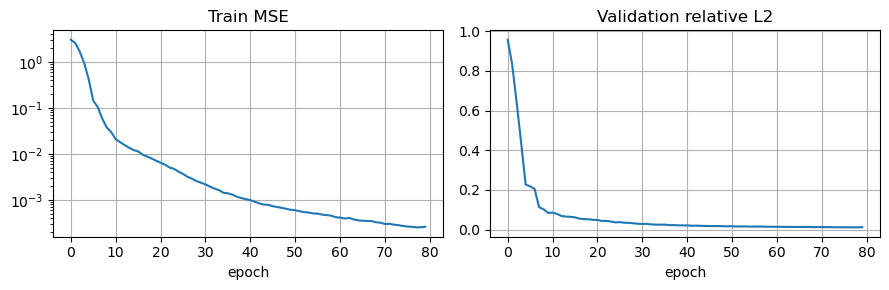

Test relative L2: mean=0.0112, median=0.0108, max=0.0147


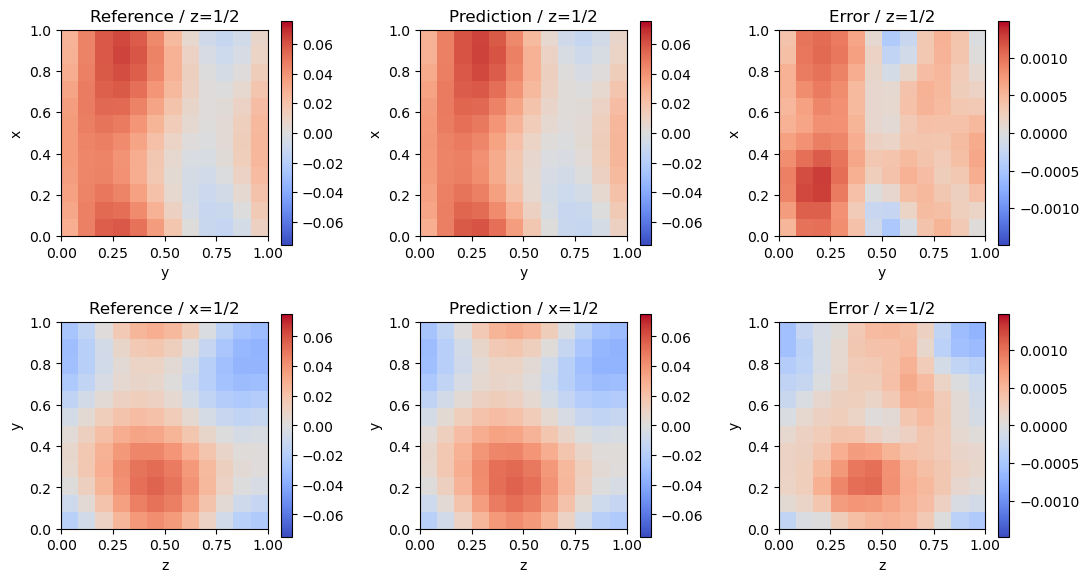

In [4]:
model = FNO3d()
print("parameters:",sum(p.numel() for p in model.parameters()))
history = fit(model,ftrain[:,None],vtrain,fval[:,None],vval,
              steps=epochs(80),batch=8,lr=0.003)
plot_history(history)
pred,error = report(model,ftest[:,None],vtest)
show_volume_slices(vtest/SCALE,pred/SCALE)

## 3. 跨网格：同一函数、不同离散表示

用原来的测试系数采样 $18^3$ 网格，不更改模型参数。网格每轴加倍，体素数增加八倍；训练内存还包括梯度、复数频谱和优化器状态。因此先用小网格建立流程，再提高网格与宽度。

误差按整个三维体积计算，切片仅用于可视化，不能代替体积误差。

Test relative L2: mean=0.0112, median=0.0108, max=0.0147


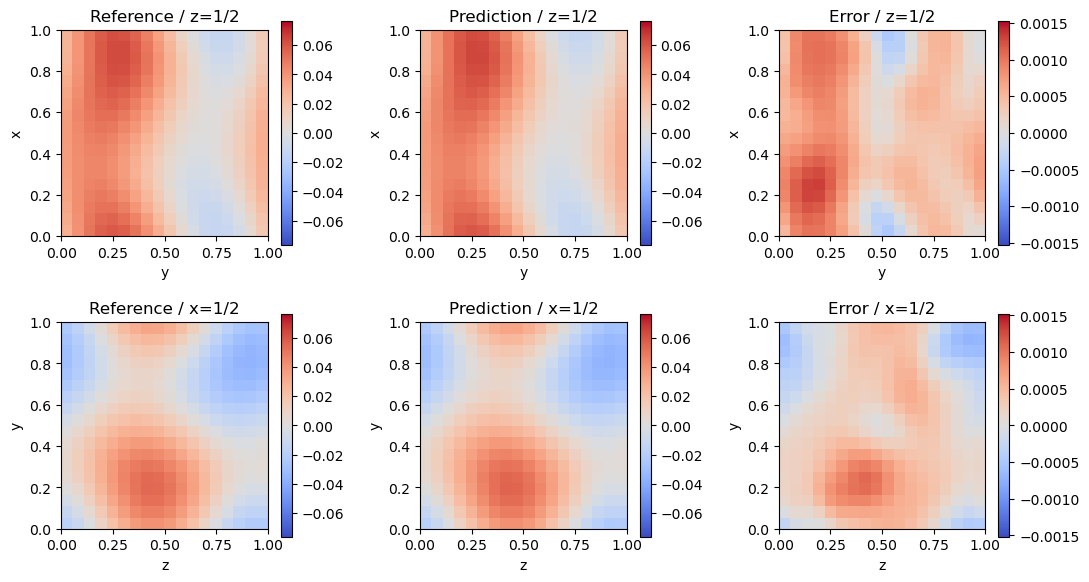

coarse relative L2: 0.011213538236916065 fine: 0.01121513545513153
Odd-grid check: torch.Size([1, 13, 13, 13])


In [5]:
NFINE = 12 if SMOKE else 18
finef = field3d(atest,NFINE)
finev = SCALE*screened_poisson3d(finef)
finepred,fineerror = report(model,finef[:,None],finev)
show_volume_slices(finev/SCALE,finepred/SCALE)
print("coarse relative L2:",error.mean().item(),"fine:",fineerror.mean().item())
odd = field3d(atest[:1],13)
model.eval()
with torch.no_grad(): odd_prediction = model(odd[:,None].to(DEVICE)).cpu()
assert odd_prediction.shape==(1,13,13,13)
print("Odd-grid check:",odd_prediction.shape)

## 4. 解误差与 PDE 残差

对预测恢复物理量，再计算 $-\Delta u+u-f$。二阶导数会放大高频误差，所以两种指标不一定同幅度变化。以双精度计算诊断，减少频谱导数的舍入放大。

In [6]:
physical = (pred/SCALE).double()
lam = laplace_symbol3d(physical.shape[-3:],dtype=torch.float64)
raw_residual = torch.fft.irfftn((1+lam)*torch.fft.rfftn(physical,dim=(-3,-2,-1)),
                               s=physical.shape[-3:],dim=(-3,-2,-1))-ftest.double()
relative_residual = raw_residual.flatten(1).norm(dim=1)/ftest.double().flatten(1).norm(dim=1)
print("Raw relative PDE residual:",relative_residual.mean().item())

Raw relative PDE residual: 0.06403239791313334


**练习：** ① 临时去掉三个角块，比较含负分量波矢的预测；② 增加输入频带并比较 modes=2/3/4；③ 将反应项改为 $\alpha u$ 并作为条件输入；④ 为长方体网格写各轴实际长度对应的 FFT 波数。

**自检：** 当前跨网格实验始终是同一类光滑函数。原始高频信息未被训练网格采样时，更密的输出网格无法凭空恢复它。